# Sistema Especialista com Aprendizado Supervisionado: Orientação de Recrutas em Formação

**Curso de Formação:** Inteligência Artificial e LFA |

**Comando da Instrução:** Profa. Kadidja Valéria

**Efetivo do grupo (integrantes):** Emmanuel Ferreira Gomes e João Pedro Reis Rios

> *Treino duro, combate fácil.*

**Ordem do dia:** treinar o modelo, testar com casos novos e só então colocá-lo em operação. Nada de ir para a missão sem passar pela instrução.

Neste trabalho, a tropa (nós) treinou uma árvore de decisão para reconhecer o perfil de um recruta e passou essa informação ao Estado-Maior, que é o nosso sistema especialista e recomenda a atividade de instrução mais adequada. Escolhemos o tema da formação de recrutas porque é terreno que conhecemos de perto: já pagamos flexão, já levamos bronca de sargento e já erramos o pé na ordem unida.

**Aviso ao efetivo:** todos os dados são simulados. Nenhum recruta real foi mobilizado, e o exercício é puramente didático. Não serve para julgar a patente nem o caráter de ninguém. Fim do aviso, voltem às fileiras.

## Parte do Instrutor (respostas à leitura)

**O que é aprendizado de máquina?** É quando o computador aprende o padrão a partir de exemplos, em vez de o comandante escrever cada ordem à mão. O modelo é adestrado com os dados e depois usa o que aprendeu para reconhecer casos novos, como um cabo que já viu muito recruta, bate o olho na tropa em forma e já sabe quem é o bizonho.

**O que são atributos e rótulos?** Os atributos (X) são as informações que o recruta apresenta durante a formação. No nosso trabalho são o desempenho no TAF e o aproveitamento nas avaliações de instrução. O rótulo (y) é a resposta oficial que o modelo precisa aprender a prever, a classificação do recruta, que aqui é o perfil: acompanhamento ou autonomia.

**Como a classificação difere da regressão?** Na classificação a resposta é uma categoria, um pelotão onde o recruta é alocado, como acompanhamento ou autonomia. Na regressão a resposta é um número contínuo, como o tempo estimado de instrução em horas. O nosso problema é de classificação: ou entra numa fileira ou entra na outra.

**Por que separar treino e teste?** O treino é a instrução, em que o modelo aprende. O teste é a prova de campo, em que ele enfrenta casos que nunca viu. Se avaliássemos com os mesmos dados do treino, a nota provaria só que o recruta decorou o gabarito, e não que sabe cumprir a missão.

## 1. Definição do problema (ordem de operações)

**Situação:** durante a formação, o instrutor precisa decidir qual atividade recomendar para cada recruta, e a tropa é grande, a hora é curta e o rancho não espera.

**Missão:** prever o perfil de cada recruta com uma árvore de decisão e, a partir dele, recomendar a atividade de instrução mais adequada.

**Execução:** o sistema opera em duas fases. Na primeira, a árvore é adestrada com exemplos e reconhece o perfil. Na segunda, o regulamento escrito por nós usa esse reconhecimento e emite a ordem.

**Apoio logístico:** Google Colab, pandas, scikit-learn e matplotlib. Munição e ração a cargo do próprio grupo.

**Comando e comunicações:** a informação sobre a dificuldade em ordem unida vem do instrutor, que também dá a palavra final. O sistema só informa qual artigo do regulamento aplicou e por quê. Comandante manda, sistema assessora.

Nosso sistema reúne dois tipos de conhecimento:

| Componente | De onde vem | Função no dispositivo |
|---|---|---|
| Árvore de decisão (aprendizado supervisionado) | Exemplos rotulados, ou seja, a instrução | Reconhece o perfil: acompanhamento ou autonomia |
| Regras R1 a R4 (sistema especialista) | Nossa experiência de caserna com instrução de recrutas | Combinam o perfil reconhecido com um fato informado e emitem a ordem |

- **Atributos (X), o que o recruta apresenta na formação:** `taf_percentual` (desempenho no TAF, de 0 a 100) e `instrucao_percentual` (aproveitamento nas avaliações de instrução, de 0 a 100).
- **Rótulo (y), a classificação do recruta:** `perfil`, com as classes `acompanhamento` (o bizonho que precisa do instrutor no pé) e `autonomia` (o recruta que se vira sozinho e já pode ficar de sentinela sem ninguém dormir de vista).
- **Fato informado pelo instrutor:** `dificuldade_ordem_unida` (`True` ou `False`), observada no pátio. É o instrutor que vê se o recruta ainda erra o pé esquerdo e marcha torto na ala.
- **Saída, a ordem que desce da cadeia de comando:** a recomendação de atividade, o artigo do regulamento aplicado e a justificativa.

As regras são conhecimento de doutrina, escritas por quem já viveu a formação de recrutas. Elas não foram aprendidas dos dados, e é justamente essa a diferença entre um sistema especialista (obedece ao regulamento) e um modelo supervisionado (aprende na marra, no pátio).

| Regra | Se (perfil reconhecido + fato) | Então (ordem emitida) | Por quê (justificativa) |
|---|---|---|---|
| R1 | acompanhamento + dificuldade em ordem unida | Reforço com o instrutor | Desempenho baixo com falha específica pede correção direta e repetição acompanhada: "de novo, e de novo, até sair em forma" |
| R2 | acompanhamento + sem dificuldade | Instrução supervisionada e revisão dos fundamentos | Nesse caso o problema tende a ser a base geral, e não um ponto isolado. Volta ao básico, soldado |
| R3 | autonomia + dificuldade em ordem unida | Treino específico de ordem unida | Falha pontual em quem rende bem pede treino focado, sem acompanhamento constante |
| R4 | autonomia + sem dificuldade | Auxiliar de instrução ou cmt de grupo | Quem rende bem e não tem dificuldade pode apoiar os demais: está promovido, na prática, a monitor |

## 2. Preparando o ambiente (apoio logístico: conferindo o material)

In [10]:
# Conferência do material bélico (bibliotecas)
# pandas: livro de chamada (manipulação de dados) | matplotlib: mapas de situação (gráficos)
import pandas as pd
import matplotlib.pyplot as plt
# Divisão do efetivo em instrução e prova de campo (treino e teste)
from sklearn.model_selection import train_test_split
# Árvore de decisão e ferramentas para ler o plano de operações aprendido
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree
# Métricas do relatório de missão
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

print("Material conferido. Sem alteração no apoio logístico!")

Material conferido. Sem alteração no apoio logístico!


## 3. Dataset rotulado (reconhecimento do efetivo simulado)

Informações sobre os dados, como manda o regulamento:

- **Efetivo:** 40 exemplos, sendo 21 de autonomia e 19 de acompanhamento. Pelotão pequeno, mas bem apresentado.
- **Origem:** dados simulados, criados por nós. Nenhum recruta real entrou em forma: é tudo simulado, e quem disser o contrário vai pagar flexão.
- **Critério de rotulagem:** o recruta é `autonomia` quando tem 60% ou mais no TAF **e** na instrução. Se algum dos dois ficar abaixo, é `acompanhamento`, e o bizonho vai para o reforço.
- **Ajuste manual:** em 3 casos de fronteira (coluna `rotulo_ajustado = sim`), o rótulo foi decidido por julgamento do comandante e não pela regra dos 60%. Fizemos isso de propósito, para simular a subjetividade que existe em rotulagem real: aquele recruta que fica no limite da linha e o instrutor decide no olho, "esse passa, esse não passa".
- **Quem rotulou:** nós mesmos, com base na experiência de instrução. Em um projeto de verdade, é preciso registrar no boletim qual instrutor rotulou e com quais evidências.

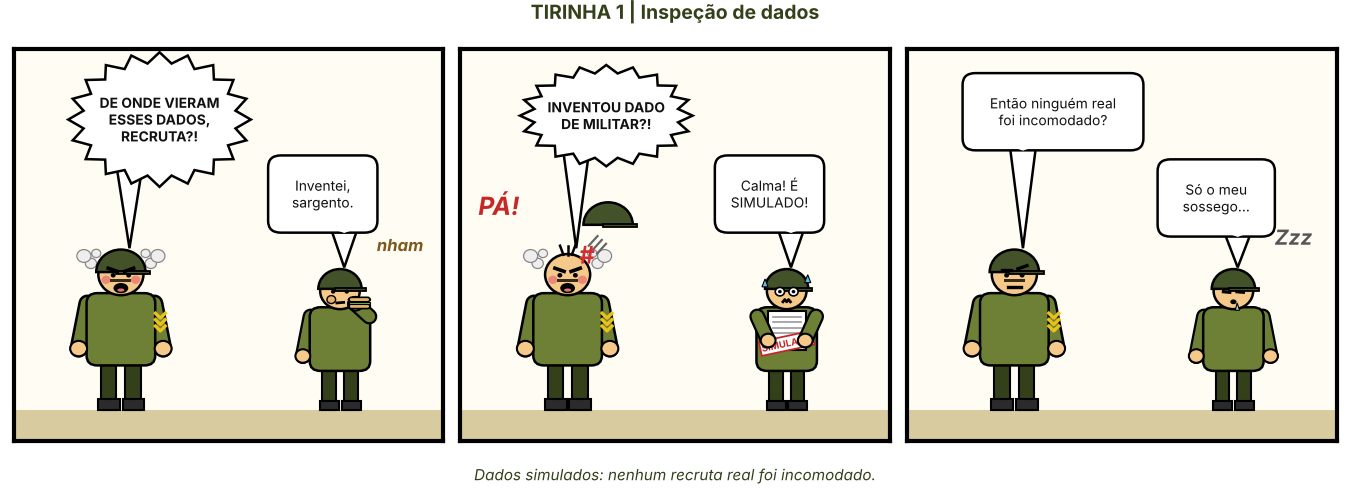

In [11]:
# Efetivo SIMULADO de recrutas (nenhum dado real). 40 exemplos em forma, formados em ordem de numeração
efetivo = pd.DataFrame({
    "id": [
        "R01", "R02", "R03", "R04", "R05", "R06", "R07", "R08",
        "R09", "R10", "R11", "R12", "R13", "R14", "R15", "R16",
        "R17", "R18", "R19", "R20", "R21", "R22", "R23", "R24",
        "R25", "R26", "R27", "R28", "R29", "R30", "R31", "R32",
        "R33", "R34", "R35", "R36", "R37", "R38", "R39", "R40"
    ],
    "taf_percentual": [
        59, 70, 100, 76, 79, 98, 56, 46,
        74, 51, 57, 65, 87, 30, 100, 39,
        100, 32, 76, 92, 50, 84, 39, 78,
        95, 82, 78, 59, 92, 82, 54, 37,
        99, 95, 94, 48, 65, 90, 89, 100
    ],
    "instrucao_percentual": [
        47, 87, 85, 54, 66, 93, 56, 94,
        92, 54, 47, 80, 44, 45, 71, 42,
        36, 36, 98, 80, 38, 84, 46, 81,
        65, 65, 87, 99, 50, 62, 69, 49,
        56, 75, 82, 36, 65, 98, 61, 40
    ],
    "perfil": [
        "acompanhamento", "autonomia", "autonomia", "autonomia",
        "autonomia", "autonomia", "acompanhamento", "acompanhamento",
        "autonomia", "acompanhamento", "acompanhamento", "autonomia",
        "acompanhamento", "acompanhamento", "autonomia", "acompanhamento",
        "acompanhamento", "acompanhamento", "autonomia", "autonomia",
        "acompanhamento", "autonomia", "acompanhamento", "autonomia",
        "autonomia", "autonomia", "autonomia", "autonomia",
        "acompanhamento", "autonomia", "acompanhamento", "acompanhamento",
        "acompanhamento", "autonomia", "autonomia", "acompanhamento",
        "acompanhamento", "autonomia", "autonomia", "acompanhamento"
    ],
    "rotulo_ajustado": [
        "nao", "nao", "nao", "sim", "nao", "nao",
        "nao", "nao", "nao", "nao", "nao", "nao",
        "nao", "nao", "nao", "nao", "nao", "nao",
        "nao", "nao", "nao", "nao", "nao", "nao",
        "nao", "nao", "nao", "sim", "nao", "nao",
        "nao", "nao", "nao", "nao", "nao", "nao",
        "sim", "nao", "nao", "nao"
    ]
})

# Passa a tropa em revista e confere a distribuição por classe (se o pelotão está equilibrado)
print(efetivo.to_string(index=False))
print("\nChamada por classe:")
print(efetivo["perfil"].value_counts())
print("\nRótulos ajustados na mão pelo comandante (casos de fronteira):")
print(efetivo[efetivo["rotulo_ajustado"] == "sim"].to_string(index=False))

 id  taf_percentual  instrucao_percentual         perfil rotulo_ajustado
R01              59                    47 acompanhamento             nao
R02              70                    87      autonomia             nao
R03             100                    85      autonomia             nao
R04              76                    54      autonomia             sim
R05              79                    66      autonomia             nao
R06              98                    93      autonomia             nao
R07              56                    56 acompanhamento             nao
R08              46                    94 acompanhamento             nao
R09              74                    92      autonomia             nao
R10              51                    54 acompanhamento             nao
R11              57                    47 acompanhamento             nao
R12              65                    80      autonomia             nao
R13              87                    44 acompanha

## 4. Separando treino e teste (quem vai para a instrução e quem vai para a prova de campo)

O `X` guarda os atributos e o `y` guarda o rótulo, e o rótulo nunca entra no `X`: gabarito não se leva para a prova. Reservamos 25% do efetivo para a prova de campo, o que dá 30 exemplos de treino (instrução) e 10 de teste (prova). O `stratify=y` mantém a proporção das classes nos dois grupamentos, para ninguém reclamar de pelotão desfalcado, e o `random_state=42` deixa a divisão reproduzível, como toda boa escala de serviço.

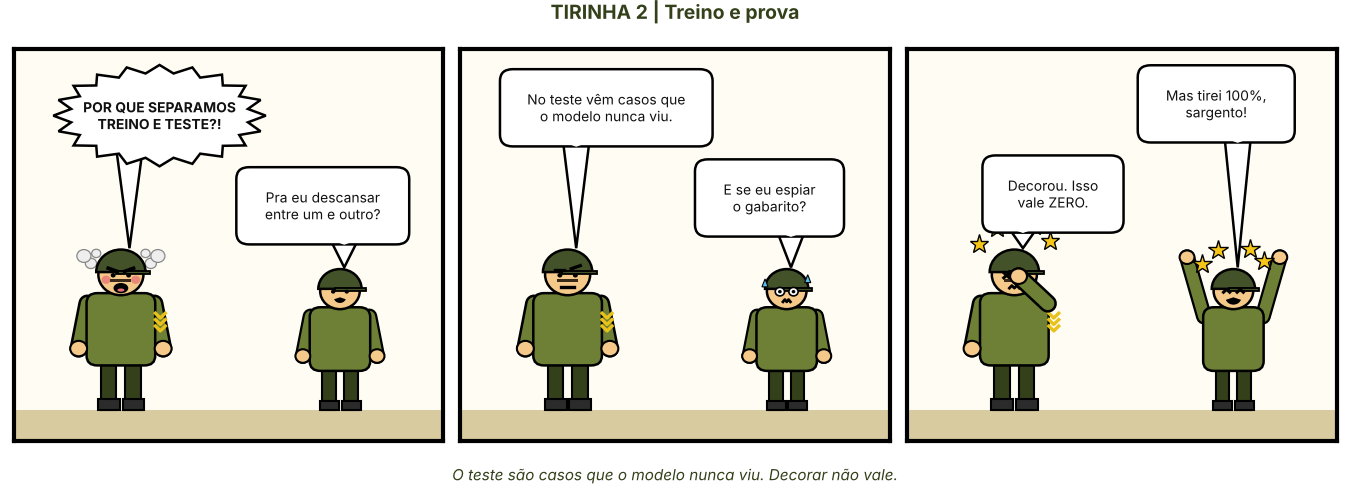

In [12]:
# X = atributos | y = rótulo (o gabarito fica fora do X)
X = efetivo[["taf_percentual", "instrucao_percentual"]]
y = efetivo["perfil"]

# 75% instrução (treino) / 25% prova de campo (teste), preservando a proporção das classes
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

print("Instrução (treino):", len(X_treino), "| Prova de campo (teste):", len(X_teste))
print("\nClasses na prova de campo:")
print(y_teste.value_counts())

Instrução (treino): 30 | Prova de campo (teste): 10

Classes na prova de campo:
perfil
acompanhamento    5
autonomia         5
Name: count, dtype: int64


## 5. Treinando e avaliando (hora da prova de campo)

O `fit` é a instrução: a árvore aprende os padrões usando somente o treino. O `predict` é a chamada da prova, em que ela gera os reconhecimentos para o teste. A acurácia é a fração de acertos na prova. Na matriz de confusão, que é o nosso quadro dos baixados e dos acertos, as linhas são as classes reais e as colunas são as previstas.

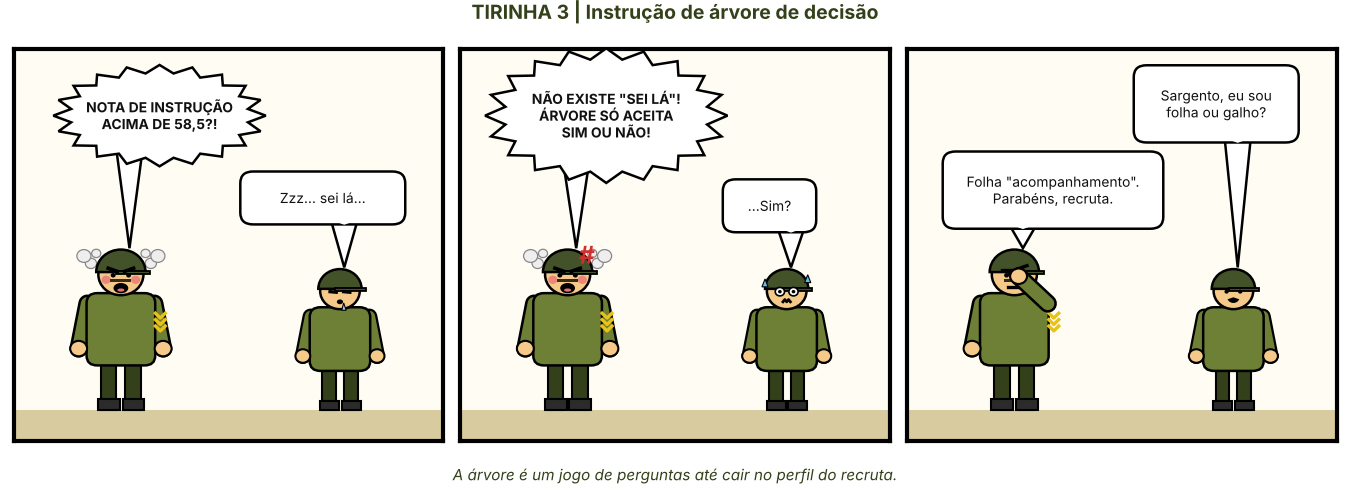

Acurácia na instrução (treino): 93.3%
Acurácia na prova de campo (teste): 100.0%
                acompanhamento  autonomia
acompanhamento               5          0
autonomia                    0          5


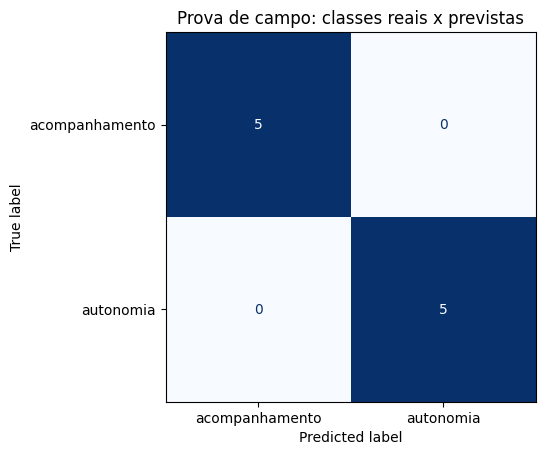

Plano de operações aprendido (condições da árvore):
|--- instrucao_percentual <= 58.50
|   |--- instrucao_percentual <= 50.50
|   |   |--- weights: [8.00, 0.00] class: acompanhamento
|   |--- instrucao_percentual >  50.50
|   |   |--- weights: [3.00, 1.00] class: acompanhamento
|--- instrucao_percentual >  58.50
|   |--- taf_percentual <= 56.50
|   |   |--- weights: [2.00, 0.00] class: acompanhamento
|   |--- taf_percentual >  56.50
|   |   |--- weights: [1.00, 15.00] class: autonomia



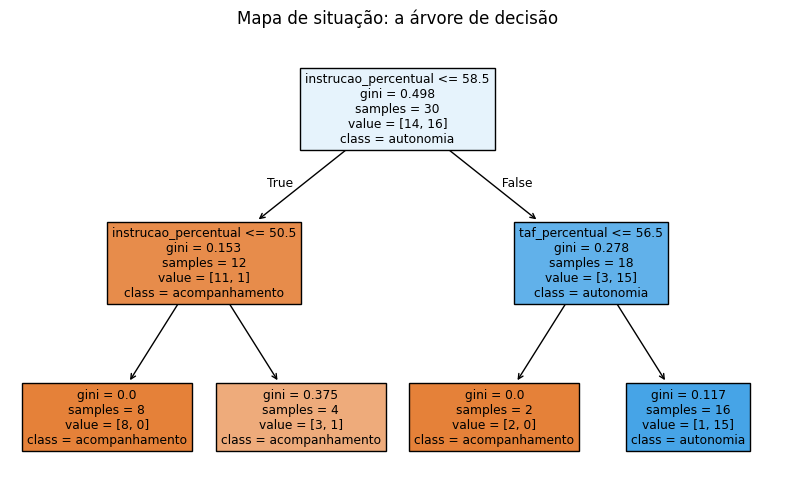

In [13]:
# Árvore de decisão com profundidade máxima 2 (para o recruta não decorar o terreno)
sargento = DecisionTreeClassifier(max_depth=2, random_state=42)
sargento.fit(X_treino, y_treino)

# Reconhecimento dos recrutas na prova de campo (conjunto de teste)
chamada_prevista = sargento.predict(X_teste)

print(f"Acurácia na instrução (treino): {sargento.score(X_treino, y_treino):.1%}")
print(f"Acurácia na prova de campo (teste): {accuracy_score(y_teste, chamada_prevista):.1%}")

# Quadro dos baixados e dos acertos (linhas = real, colunas = previsto)
classes = ["acompanhamento", "autonomia"]
quadro_dos_baixados = confusion_matrix(y_teste, chamada_prevista, labels=classes)
print(pd.DataFrame(quadro_dos_baixados, index=classes, columns=classes))

ConfusionMatrixDisplay(quadro_dos_baixados, display_labels=classes).plot(cmap="Blues", colorbar=False)
plt.title("Prova de campo: classes reais x previstas")
plt.show()

# Plano de operações aprendido pela árvore
print("Plano de operações aprendido (condições da árvore):")
print(export_text(sargento, feature_names=list(X.columns), show_weights=True))

plt.figure(figsize=(10, 6))
plot_tree(sargento, feature_names=list(X.columns),
          class_names=list(sargento.classes_), filled=True)
plt.title("Mapa de situação: a árvore de decisão")
plt.show()

### 5.1 Entendendo os termos da árvore (lendo a carta topográfica)

Cada caixa da figura acima mostra três números que explicam como a árvore decidiu:

- **Gini:** mede o quanto a fileira daquela caixa está bagunçada: quanto mais misturada, mais o sargento grita. Vale `0.0` quando todos os recrutas ali são da mesma classe e chega perto de `0.5` quando está meio a meio. Na raiz o gini é `0.498`, porque há 14 de acompanhamento e 16 de autonomia: a tropa está toda misturada, ninguém sabe onde é a direita e onde é a esquerda. Já as folhas com `[8, 0]` e `[2, 0]` têm gini `0.0`, ou seja, todos em forma, cobertos e alinhados, sargento satisfeito.
- **Samples:** o efetivo da caixa, isto é, quantos recrutas do treino chegaram ali. A raiz tem `30` e, depois da primeira pergunta (`instrucao_percentual <= 58.5`), a esquerda fica com `12` e a direita com `18`: o pelotão racha em dois grupamentos.
- **Value:** a chamada nominal da caixa, com quantos recrutas de cada classe estão ali, na ordem `[acompanhamento, autonomia]`. Na raiz é `[14, 16]` e, na folha da esquerda, é `[8, 0]`, ou seja, os 8 são todos de acompanhamento. Presente, sargento!

**Interpretação:** os dados são simulados e a prova de campo tem só 10 casos, então mesmo 100% de acerto não prova eficácia em combate real. A árvore mostra as condições aprendidas, e as regras de recomendação foram escritas por nós, no regulamento.

### 5.2 Análise dos resultados (relatório da missão)

- **Resultado da missão:** a árvore acertou os 10 casos da prova de campo (100%), e o quadro dos baixados ficou zerado: nenhum baixado. Na instrução a acurácia foi de 93,3%, porque a árvore errou 2 dos 30 exemplos. Missão cumprida na prova, mas com ressalvas, como veremos a seguir.
- **Isso prova que o modelo está pronto para o combate? Negativo.** São só 10 casos de teste, os dados são simulados e os rótulos seguem uma regra simples que nós mesmos baixamos em ordem de serviço (60% nos dois atributos). A árvore basicamente redescobriu o nosso regulamento. Com dados reais, que têm mais ruído e instrutores que pensam diferente, o resultado seria menor. Terreno real não perdoa.
- **O que a árvore aprendeu:** ela separa primeiro por `instrucao_percentual` (corte em 58,5) e, no ramo da instrução alta, usa o `taf_percentual` (corte em 56,5). Os cortes não ficaram exatamente em 60. Bizu: a árvore traça a linha de demarcação no ponto médio entre valores vizinhos do treino.
- **Por que errou na instrução:** com `max_depth=2`, a árvore não consegue representar a regra completa dos dois limites em todos os ramos. Conferindo a escala, os dois erros de treino são justamente dois bizonhos de fronteira que ajustamos na mão: o recruta com TAF 76 e instrução 54, rotulado como autonomia, e o recruta com TAF 65 e instrução 65, rotulado como acompanhamento. Ou seja, o erro veio do rótulo subjetivo do comandante e não de defeito do equipamento.
- **Cuidado com a prova de campo:** não vale ficar ajustando parâmetros, como a profundidade, olhando para esta mesma prova, porque isso é repetir o teste até acertar, e quem faz isso vai ser engrenado pelo instrutor, com direito a flexão e faxina no alojamento. Se precisássemos ajustar, o certo seria usar um conjunto de validação separado, o nosso simulado de campo.

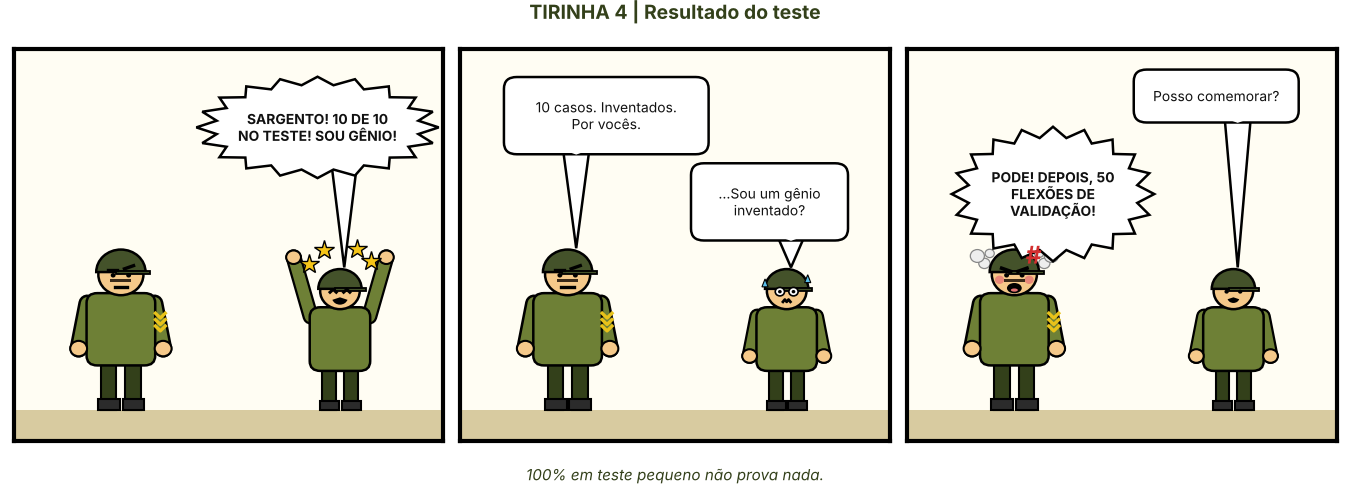

## 6. Base de conhecimento e motor de inferência (o regulamento e quem o aplica)

Aqui o reconhecimento da árvore vira um fato de inteligência. O outro fato, `dificuldade_ordem_unida`, vem do instrutor, direto do pátio. A base de conhecimento é o nosso regulamento, e o motor de inferência é o oficial de serviço que o consulta: ele procura o artigo que combina com os dois fatos e devolve a ordem emitida, o artigo aplicado, a fonte dele e a justificativa. Tudo por escrito e com carimbo, porque na caserna o que não está no papel não aconteceu.

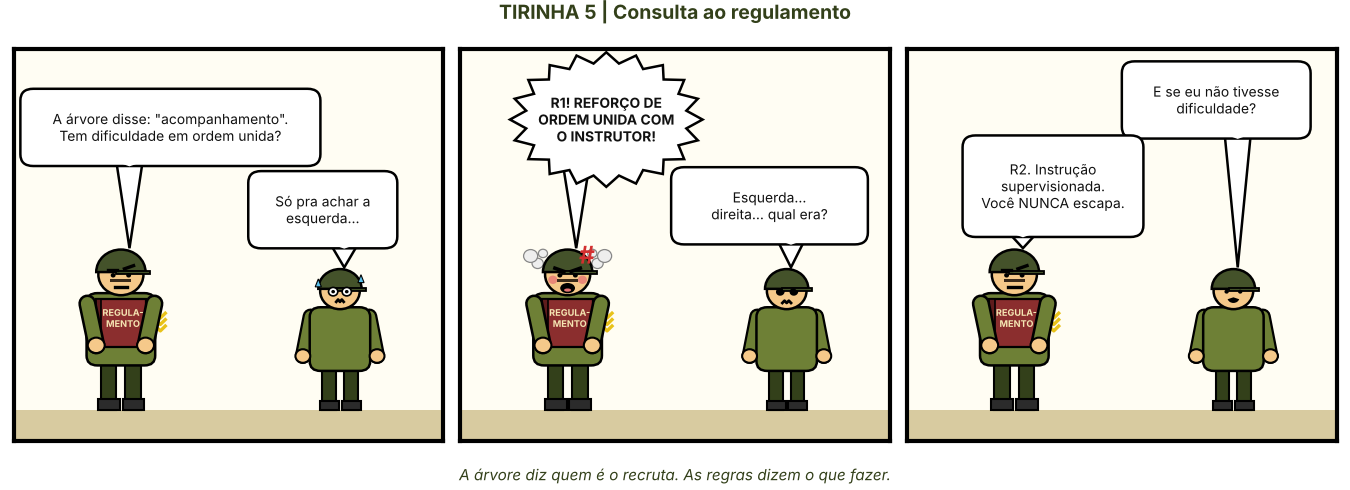

In [14]:
# Base de conhecimento: o regulamento, escrito por gente de caserna (conhecimento de doutrina)
FONTE_DO_REGULAMENTO = "Experiência de instrução na formação de recrutas (autores)"
regulamento = [
    {"id": "R1", "perfil": "acompanhamento", "dificuldade_ordem_unida": True,
     "acao": "Reforço de ordem unida com o instrutor, no pé do sargento até sair em forma.", "origem": FONTE_DO_REGULAMENTO,
     "justificativa": "Desempenho geral baixo somado a falha específica pede correção direta e repetição acompanhada."},
    {"id": "R2", "perfil": "acompanhamento", "dificuldade_ordem_unida": False,
     "acao": "Instrução supervisionada pelo instrutor, com revisão dos fundamentos (volta ao básico, soldado).", "origem": FONTE_DO_REGULAMENTO,
     "justificativa": "Sem falha pontual, o problema tende a ser a base geral; o foco é supervisão e revisão dos fundamentos."},
    {"id": "R3", "perfil": "autonomia", "dificuldade_ordem_unida": True,
     "acao": "Treino específico de ordem unida.", "origem": FONTE_DO_REGULAMENTO,
     "justificativa": "Bom desempenho geral com falha pontual dispensa acompanhamento constante; basta treino focado no ponto fraco."},
    {"id": "R4", "perfil": "autonomia", "dificuldade_ordem_unida": False,
     "acao": "Função de auxiliar de instrução ou cmt de grupo.", "origem": FONTE_DO_REGULAMENTO,
     "justificativa": "Recruta que rende bem e não tem dificuldade pode ser aproveitado para apoiar os demais."},
]

# Motor de inferência: o oficial de serviço procura o artigo cujas condições coincidem com os fatos
def consultar_regulamento(perfil, dificuldade_ordem_unida):
    for regra in regulamento:
        if (regra["perfil"] == perfil and
                regra["dificuldade_ordem_unida"] == dificuldade_ordem_unida):
            return {
                "perfil_reconhecido": perfil,
                "artigo_aplicado": regra["id"],
                "ordem_emitida": regra["acao"],
                "fonte_do_artigo": regra["origem"],
                "justificativa_do_artigo": regra["justificativa"],
                "parte_do_sistema": (
                    f"Perfil reconhecido: {perfil}; dificuldade em ordem unida: "
                    f"{dificuldade_ordem_unida}."
                ),
            }
    raise ValueError("Nenhum artigo do regulamento compatível com os fatos. Solicitar orientação ao comandante.")

## 7. Integrando o modelo ao sistema especialista (cadeia de comando)

Aqui a informação sobe e desce a cadeia de comando: a árvore reconhece o perfil e repassa ao regulamento. A função abaixo confere as credenciais das entradas, usa a árvore para reconhecer o perfil (primeiro fato), recebe a dificuldade informada pelo instrutor (segundo fato) e aplica o regulamento. Se os valores estiverem fora dos intervalos vistos na instrução, ela emite um aviso, porque o reconhecimento pode ser menos confiável: terreno desconhecido, avançar com cautela.

In [15]:
def dar_ordem_ao_recruta(taf, instrucao, dificuldade_ordem_unida):
    # Revista das entradas: documento errado não passa pela guarda
    if not 0 <= taf <= 100:
        raise ValueError("TAF deve estar entre 0 e 100.")
    if not 0 <= instrucao <= 100:
        raise ValueError("Instrução deve estar entre 0 e 100.")
    if not isinstance(dificuldade_ordem_unida, bool):
        raise ValueError("Dificuldade em ordem unida deve ser True ou False.")

    novo_recruta = pd.DataFrame([{
        "taf_percentual": taf,
        "instrucao_percentual": instrucao
    }])

    # 1. Reconhecimento: a árvore (o sargento) prevê o perfil
    perfil = sargento.predict(novo_recruta)[0]

    # 2. Inferência: o regulamento usa o reconhecimento como fato
    resultado = consultar_regulamento(perfil, dificuldade_ordem_unida)

    # Confere se o recruta está fora do terreno reconhecido na instrução
    fora = any(
        not X_treino[c].min() <= novo_recruta[c].iloc[0] <= X_treino[c].max()
        for c in X.columns
    )
    resultado["observacao_do_oficial"] = (
        "Entrada fora dos intervalos observados na instrução: terreno desconhecido."
        if fora else "Exemplo didático; ordem sujeita a revisão do instrutor, que é quem manda."
    )
    return resultado

## 8. Três casos novos, que a árvore não viu na instrução (missão em campo)

In [16]:
missoes = [(40, 45, True), (85, 80, False), (58, 90, True)]

for i, (taf, instrucao, dificuldade) in enumerate(missoes, 1):
    print(f"\nMISSÃO {i}: TAF {taf}%; instrução {instrucao}%; dificuldade em ordem unida = {dificuldade}")
    for campo, valor in dar_ordem_ao_recruta(taf, instrucao, dificuldade).items():
        print(f"{campo}: {valor}")


MISSÃO 1: TAF 40%; instrução 45%; dificuldade em ordem unida = True
perfil_reconhecido: acompanhamento
artigo_aplicado: R1
ordem_emitida: Reforço de ordem unida com o instrutor, no pé do sargento até sair em forma.
fonte_do_artigo: Experiência de instrução na formação de recrutas (autores)
justificativa_do_artigo: Desempenho geral baixo somado a falha específica pede correção direta e repetição acompanhada.
parte_do_sistema: Perfil reconhecido: acompanhamento; dificuldade em ordem unida: True.
observacao_do_oficial: Exemplo didático; ordem sujeita a revisão do instrutor, que é quem manda.

MISSÃO 2: TAF 85%; instrução 80%; dificuldade em ordem unida = False
perfil_reconhecido: autonomia
artigo_aplicado: R4
ordem_emitida: Função de auxiliar de instrução ou cmt de grupo.
fonte_do_artigo: Experiência de instrução na formação de recrutas (autores)
justificativa_do_artigo: Recruta que rende bem e não tem dificuldade pode ser aproveitado para apoiar os demais.
parte_do_sistema: Perfil recon

**Sobre a Missão 3:** o recruta tem TAF 58%, abaixo dos 60% do nosso critério de rotulagem, mas a árvore reconheceu autonomia. Isso não é erro de código nem insubordinação: a árvore aprende a partir dos exemplos e não da ordem de serviço que escrevemos. O corte do TAF em 56,5 fica no meio entre um recruta com TAF 54 (acompanhamento) e o recruta R28, com TAF 59, que ajustamos manualmente como autonomia. É um caso de fronteira, onde o modelo tende a divergir do regulamento, e serve de exemplo para o ponto dos exemplos pouco representados, na seção 10.

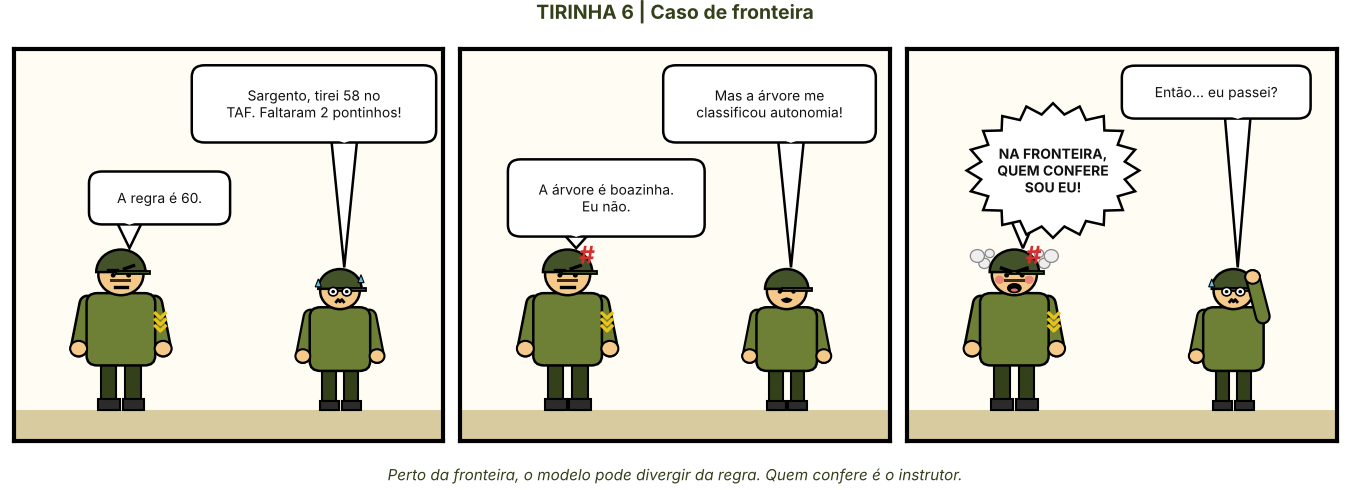

## 9. Comparação: mesmos números, outra ordem sobre ordem unida

Aqui mantemos o TAF e a instrução iguais e mudamos só a dificuldade em ordem unida. O reconhecimento da árvore continua o mesmo, e quem muda a ordem emitida é o sistema especialista, porque o segundo fato entra no regulamento. Mesmo recruta, mesmo uniforme, outro artigo.

In [17]:
for dificuldade in (True, False):
    r = dar_ordem_ao_recruta(40, 45, dificuldade)
    print(f"dificuldade_ordem_unida={dificuldade} -> perfil: {r['perfil_reconhecido']} | {r['artigo_aplicado']} | {r['ordem_emitida']}")

# Teste com entrada fora do terreno da instrução: deve gerar aviso
print("\nEntrada fora do intervalo da instrução:")
print(dar_ordem_ao_recruta(20, 30, False)["observacao_do_oficial"])

dificuldade_ordem_unida=True -> perfil: acompanhamento | R1 | Reforço de ordem unida com o instrutor, no pé do sargento até sair em forma.
dificuldade_ordem_unida=False -> perfil: acompanhamento | R2 | Instrução supervisionada pelo instrutor, com revisão dos fundamentos (volta ao básico, soldado).

Entrada fora do intervalo da instrução:
Entrada fora dos intervalos observados na instrução: terreno desconhecido.


## 10. Erros, limitações e cuidados (pontos fracos e cuidados com o efetivo)

- **Efetivo reduzido.** Com 40 exemplos e só 10 na prova de campo, a avaliação é instável: é pelotão pequeno demais para tirar conclusão. Acertar 100% nesse cenário pede cautela, pois bom soldado desconfia de vitória fácil.
- **Dados simulados e rótulos circulares.** Os rótulos seguem uma regra que nós mesmos baixamos, então o modelo só reaprende o nosso regulamento. É como o sargento dar a prova e corrigir com o próprio gabarito. Isso não mostra que ele funcionaria em uma formação de verdade.
- **Rótulos subjetivos.** Os 3 casos de fronteira dependem de julgamento. Um instrutor acha o recruta bizonho, outro acha que ele está pronto para a missão, e o modelo herdaria essa divergência de comando.
- **Exemplos pouco representados.** Há poucos casos perto da fronteira de 60%, que é a linha de contato, onde a decisão é mais difícil, e só 3 deles têm rótulo ajustado por julgamento. Esses recrutas que fogem do padrão, com combinações que o treino não cobriu, podem receber reconhecimentos menos confiáveis.
- **Só dois atributos.** O perfil de um recruta depende de muito mais do que TAF e provas de instrução, como condição de saúde, adaptação ao quartel e motivação. O modelo não enxerga nada disso, e a tropa não vive só de percentual.
- **Fato informado por uma pessoa.** A `dificuldade_ordem_unida` depende da observação do instrutor e também pode carregar viés. Sargento de mau humor enxerga ordem unida torta em todo mundo.
- **Sigilo e dados pessoais.** O desempenho de pessoas é dado sensível. Em um uso real, seria preciso anonimizar, coletar só o necessário, definir quem pode acessar e respeitar a LGPD e as normas da instituição. Informação de recruta não circula solta: só chega a quem precisa saber, e o que se fala no pelotão fica no pelotão.
- **Comando e supervisão humana.** A recomendação serve como assessoria e nunca como decisão automática sobre o recruta. O sistema mostra qual artigo do regulamento aplicou, e a decisão final é do instrutor, que comanda a instrução. Computador não tem divisa.

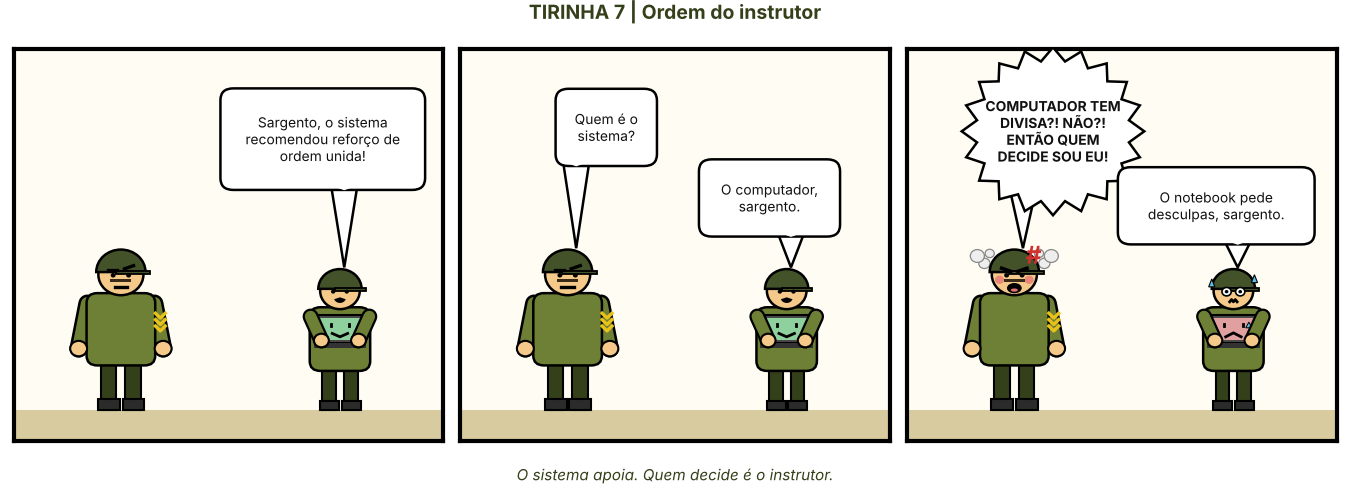

## 11. Questões de fechamento (ponto de controle)

**Qual parte da arquitetura aprende com os dados?** A árvore de decisão, que ajusta suas condições a partir dos exemplos rotulados, ou seja, a parte que passou pela instrução.

**Qual parte aplica as regras humanas do negócio?** O sistema especialista, formado pela base de conhecimento (R1 a R4, o regulamento) e pelo motor de inferência (o oficial de serviço), que combinam o perfil reconhecido com o fato informado pelo instrutor.

**Por que 100% de acerto em um teste pequeno exige cautela?** Porque com poucos casos de prova, acertar tudo pode ser sorte ou sinal de terreno fácil demais. Em dados reais, que são mais variados, o desempenho tende a cair. Por isso esse resultado não deve ser tratado como prova de que o modelo está pronto para o combate.

**Missão dada é missão cumprida.** Fim do trabalho. Sem alteração. Sentido! Estão dispensados! Fora de forma... marcheee!

## Referências (fontes de inteligência)

- IBM. Guia de Aprendizado de Máquina: https://www.ibm.com/br-pt/think/machine-learning
- IBM. Aprendizado supervisionado: https://www.ibm.com/br-pt/think/topics/supervised-learning
- scikit-learn. DecisionTreeClassifier: https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html
- scikit-learn. train_test_split: https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html